# 🛒 Shelf Monitor — Uso: análisis de góndolas
Sube fotos de góndolas y el notebook:
1. **Evalúa la calidad** de cada foto (brillo, contraste, nitidez, reflejos, resolución).
2. **Decide si hace falta el enhancer.** En modo `auto` solo mejora si detecta problemas y el modelo lo confirma (compara su detección en la foto original y en la mejorada).
3. **Reconstruye las baldas a partir de los productos detectados** (funciona con perspectiva, baldas inclinadas y módulos desfasados) y busca **huecos entre productos** de cada fila.
4. **Reporta por nivel:** ocupación, huecos, faltantes estimados y qué niveles hay que reponer.
5. **Guarda** imágenes anotadas, tablas CSV y las detecciones crudas (`detecciones.json`) en Drive.

Requiere el modelo ya entrenado en Drive (`best.pt`).

## 0. Configuración

In [5]:
from pathlib import Path

# --- Rutas ---
DRIVE_DIR  = Path('/content/drive/MyDrive/tesis_colab')
RUNS_DIR   = DRIVE_DIR / 'models/runs'
MODEL_RUN  = 'run_colab_gpu_v2-8'                 # carpeta del modelo que quieres usar
INPUT_DIR  = DRIVE_DIR / 'fotos_para_analizar'    # solo si IMAGES_SOURCE = 'carpeta'
OUTPUT_DIR = DRIVE_DIR / 'resultados'
IMAGE_EXTENSIONS = {'.bmp', '.jpeg', '.jpg', '.png', '.tif', '.tiff', '.webp'}

# --- Entrada ---
IMAGES_SOURCE = 'subir'     # 'subir' = subes fotos desde tu computadora | 'carpeta' = lee INPUT_DIR

# --- Modelo ---
CONF_THRESHOLD     = 0.35
PRODUCT_CLASS_NAME = 'producto'   # nombre de la clase de producto en tu YAML

# --- Enhancer ---
# 'auto'    = analiza la calidad y mejora solo si hace falta (y si el modelo lo confirma)
# 'siempre' = mejora todas las fotos  (úsalo si tu modelo se entrenó con el dataset mejorado)
# 'nunca'   = nunca mejora
ENHANCER_MODE = 'auto'

# --- Umbrales de calidad (ajústalos mirando las métricas que imprime el notebook) ---
UMBRALES_CALIDAD = dict(
    brillo_min=70,      # brillo medio (0-255) por debajo = foto oscura
    brillo_max=190,     # por encima = foto muy clara
    contraste_min=40,   # desviación estándar de grises por debajo = bajo contraste
    nitidez_ok=120,     # varianza del Laplaciano (a 1000 px de ancho) por debajo = algo borrosa
    nitidez_min=40,     # por debajo = muy borrosa (el enhancer no la arregla)
    resolucion_min=480, # lado menor en píxeles
    reflejo_max=0.08,   # fracción de píxeles casi blancos (reflejos / sobreexposición)
)

# --- Reporte de góndola ---
OCUP_OK        = 80     # ocupación >= esto -> OK
OCUP_ATENCION  = 50     # entre ambos -> Atención ; por debajo -> Reponer

## 1. Montar Drive e instalar dependencias

In [6]:
!pip install -q ultralytics opencv-python-headless scipy pandas matplotlib

from google.colab import drive
drive.mount('/content/drive')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DIR.mkdir(parents=True, exist_ok=True)
print("[OK] Drive montado y dependencias instaladas.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[OK] Drive montado y dependencias instaladas.


## 2. Cargar el modelo

In [7]:
from ultralytics import YOLO
from pathlib import Path

print(f"Corridas disponibles en {RUNS_DIR}:")
if Path(RUNS_DIR).exists():
    for p in sorted(Path(RUNS_DIR).glob('*')):
        estado = '✓ best.pt' if (p / 'weights' / 'best.pt').exists() else '✗ sin best.pt'
        print(f"  - {p.name}  [{estado}]")
else:
    print("  (la carpeta no existe)")

BEST_WEIGHTS = Path(RUNS_DIR) / MODEL_RUN / 'weights' / 'best.pt'


def cargar_modelo_manual():
    """Pide el modelo manualmente: subida de archivo (Colab) o ruta escrita."""
    try:
        from google.colab import files
        print("\n[!] No se encontró el modelo en la ruta configurada.")
        print("    Selecciona tu archivo .pt para subirlo...")
        subidos = files.upload()
        if not subidos:
            raise FileNotFoundError("No se subió ningún archivo.")
        nombre = next(iter(subidos))
        return Path(nombre).resolve()
    except ImportError:
        # No estamos en Colab: pedir la ruta por teclado
        ruta = input("\n[!] No se encontró el modelo. Escribe la ruta completa del archivo .pt: ").strip().strip('"').strip("'")
        ruta = Path(ruta)
        if not ruta.exists():
            raise FileNotFoundError(f"La ruta indicada no existe: {ruta}")
        return ruta


if BEST_WEIGHTS.exists():
    print(f"\n[OK] Modelo encontrado automáticamente: {BEST_WEIGHTS}")
else:
    BEST_WEIGHTS = cargar_modelo_manual()
    if BEST_WEIGHTS.suffix != '.pt':
        raise ValueError(f"El archivo debe ser .pt, recibí: {BEST_WEIGHTS.name}")

model = YOLO(str(BEST_WEIGHTS))

# Detecta solo el id de la clase de producto según los nombres del modelo
ids = [k for k, v in model.names.items() if v == PRODUCT_CLASS_NAME]
PRODUCT_CLASS = ids[0] if ids else 1
print(f"\n[OK] Modelo cargado: {BEST_WEIGHTS}")
print(f"     Clases: {model.names}  |  clase de producto = {PRODUCT_CLASS}")

Corridas disponibles en /content/drive/MyDrive/tesis_colab/models/runs:
  (la carpeta no existe)

[!] No se encontró el modelo en la ruta configurada.
    Selecciona tu archivo .pt para subirlo...


Saving best.pt to best.pt

[OK] Modelo cargado: /content/best.pt
     Clases: {0: 'vacio', 1: 'producto'}  |  clase de producto = 1


## 3. Funciones de análisis
Tres celdas que solo definen funciones:
- **Calidad y enhancer.**
- **Góndola:** las baldas se reconstruyen ajustando rectas a la base de los productos detectados (RANSAC), las filas de módulos contiguos se unen en un mismo nivel, y los huecos se miden contra el paso típico entre productos de esa fila. Los bordes (Canny) distinguen un hueco realmente vacío (`vacio`, poca textura) de un posible producto que el modelo no vio (`revisar`). Las columnas sin producto en casi todos los niveles (postes, tapas laterales) se descuentan.
- **Flujo completo por imagen.**

In [8]:
import cv2
import numpy as np

def enhance(img):
    """CLAHE en luminancia + nitidez leve (la misma función usada para el dataset mejorado)."""
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    img = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)
    blur = cv2.GaussianBlur(img, (0, 0), 2)
    return cv2.addWeighted(img, 1.4, blur, -0.4, 0)


def assess_quality(img_bgr, th=UMBRALES_CALIDAD):
    """Mide brillo, contraste, nitidez, reflejos y resolución.
    'mejorar' = problemas que el enhancer puede aliviar; 'avisos' = problemas que no."""
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Nitidez a ancho fijo, para poder comparar fotos de distinta resolución
    g = gray if w == 1000 else cv2.resize(gray, (1000, max(1, int(h * 1000 / w))), interpolation=cv2.INTER_AREA)
    nitidez = float(cv2.Laplacian(g, cv2.CV_64F).var())

    m = dict(
        resolucion=f"{w}x{h}",
        brillo=float(gray.mean()),
        contraste=float(gray.std()),
        nitidez=nitidez,
        reflejos=float((gray > 245).mean()),
    )

    mejorar, avisos = [], []
    if m['brillo'] < th['brillo_min']:      mejorar.append('oscura')
    if m['brillo'] > th['brillo_max']:      mejorar.append('muy clara')
    if m['contraste'] < th['contraste_min']: mejorar.append('bajo contraste')
    if m['nitidez'] < th['nitidez_ok']:     mejorar.append('algo borrosa')

    if m['nitidez'] < th['nitidez_min']:
        avisos.append('muy borrosa: el enhancer no la arregla, conviene volver a tomar la foto')
    if min(h, w) < th['resolucion_min']:
        avisos.append(f"resolución baja ({w}x{h}): los productos pequeños pueden no detectarse")
    if m['reflejos'] > th['reflejo_max']:
        avisos.append(f"reflejos/sobreexposición ({m['reflejos']*100:.0f}% de píxeles casi blancos)")

    m['mejorar'], m['avisos'] = mejorar, avisos
    return m

In [9]:
import cv2
import numpy as np
from dataclasses import dataclass, field


# ----------------------------------------------------------------------
# GÓNDOLA A PARTIR DE LOS PRODUCTOS DETECTADOS
#  1. Las baldas se reconstruyen ajustando rectas (RANSAC) a la base de las cajas
#     de producto: funciona con perspectiva, baldas inclinadas y módulos desfasados.
#  2. Los huecos se buscan ENTRE productos contiguos de la misma fila, comparando
#     con el paso típico de esa fila (no con el ancho de la imagen).
#  3. Los bordes (Canny) se usan para decidir si un hueco es 'vacio' (poca textura)
#     o 'revisar' (hay textura: probablemente un producto que el modelo no vio).
#  4. Un hueco que se repite en la misma columna en casi todas las filas es un
#     poste o una tapa lateral, no falta de producto: se marca 'estructura'.
# ----------------------------------------------------------------------
@dataclass
class Row:
    m: float                     # y = m * x + c  (base de los productos)
    c: float
    boxes: list = field(default_factory=list)   # (x1, y1, x2, y2), ordenadas por x
    level: int = -1

    def y_at(self, x):
        return self.m * x + self.c

    @property
    def x_min(self): return min(b[0] for b in self.boxes)
    @property
    def x_max(self): return max(b[2] for b in self.boxes)
    @property
    def mid_y(self): return float(np.mean([(b[3]) for b in self.boxes]))
    @property
    def med_w(self): return float(np.median([b[2] - b[0] for b in self.boxes]))
    @property
    def med_h(self): return float(np.median([b[3] - b[1] for b in self.boxes]))

    @property
    def pitch(self):
        xs = sorted(b[0] for b in self.boxes)
        d = [q - p for p, q in zip(xs, xs[1:]) if 0 < (q - p) < 2 * self.med_w]
        return float(np.median(d)) if d else self.med_w * 1.1


def fit_rows(boxes, img_w, min_row_products=4, slope_max=0.25, tol_frac=0.25, iters=800, seed=0):
    """Agrupa las cajas en filas (baldas) con RANSAC sobre el punto medio de la base de cada caja."""
    if len(boxes) < min_row_products:
        return []
    P = np.array([[(b[0] + b[2]) / 2, b[3]] for b in boxes], dtype=float)
    med_h = float(np.median([b[3] - b[1] for b in boxes]))
    tol = max(6.0, tol_frac * med_h)
    rng = np.random.default_rng(seed)

    remaining = np.arange(len(P))
    lines = []
    while len(remaining) >= min_row_products:
        pts = P[remaining]
        best = None
        for _ in range(iters):
            i, j = rng.choice(len(pts), 2, replace=False)
            dx = pts[j, 0] - pts[i, 0]
            if abs(dx) < 0.08 * img_w:
                continue
            m = (pts[j, 1] - pts[i, 1]) / dx
            if abs(m) > slope_max:
                continue
            c = pts[i, 1] - m * pts[i, 0]
            inl = np.abs(pts[:, 1] - (m * pts[:, 0] + c)) <= tol
            n = int(inl.sum())
            if best is None or n > best[0]:
                best = (n, m, c, inl)
        if best is None or best[0] < min_row_products:
            break
        _, m, c, inl = best
        for _ in range(2):     # re-ajuste por mínimos cuadrados con los inliers
            A = np.vstack([pts[inl, 0], np.ones(int(inl.sum()))]).T
            m, c = np.linalg.lstsq(A, pts[inl, 1], rcond=None)[0]
            inl = np.abs(pts[:, 1] - (m * pts[:, 0] + c)) <= tol
        lines.append((float(m), float(c)))
        remaining = remaining[~inl]

    if not lines:
        return []
    # Cada caja va a la recta más cercana (si está razonablemente cerca)
    rows = [Row(m, c) for m, c in lines]
    for b in boxes:
        cx = (b[0] + b[2]) / 2
        d = [abs(b[3] - r.y_at(cx)) for r in rows]
        k = int(np.argmin(d))
        if d[k] <= 2.2 * tol:
            rows[k].boxes.append(b)
    rows = [r for r in rows if len(r.boxes) >= min_row_products]
    for r in rows:
        r.boxes.sort(key=lambda b: b[0])
    return rows


def group_levels(rows, overlap_max=0.25):
    """Filas de módulos contiguos (desfasadas unos píxeles) forman un mismo nivel."""
    if not rows:
        return []
    med_h = float(np.median([r.med_h for r in rows]))
    levels = []                                   # lista de listas de filas
    for r in sorted(rows, key=lambda r: r.mid_y):
        placed = False
        for lv in levels:
            if abs(np.mean([q.mid_y for q in lv]) - r.mid_y) > 0.8 * med_h:
                continue
            ok = True
            for q in lv:
                inter = min(q.x_max, r.x_max) - max(q.x_min, r.x_min)
                if inter > overlap_max * min(q.x_max - q.x_min, r.x_max - r.x_min):
                    ok = False
                    break
            if ok:
                lv.append(r)
                placed = True
                break
        if not placed:
            levels.append([r])
    levels.sort(key=lambda lv: np.mean([q.mid_y for q in lv]))
    for k, lv in enumerate(levels):
        for r in lv:
            r.level = k
    return levels


def _gaps_in_row(row, gx0, gx1, estructura, min_gap_w_frac=0.5):
    """Huecos entre productos contiguos y hacia los extremos de la góndola.
    Al medir cada hueco se descuenta el ancho que cae en columnas estructurales (postes, tapas)."""
    p, mw = row.pitch, row.med_w
    out = []

    def efectivo(xa, xb):
        g = xb - xa
        for (ea, eb) in estructura:
            g -= max(0.0, min(xb, eb) - max(xa, ea))
        return g

    def n_missing(g):
        return int((g + 0.3 * p) / p)

    bxs = row.boxes
    tramos = [(a[2], b[0]) for a, b in zip(bxs, bxs[1:])]          # entre productos contiguos
    tramos.append((gx0, row.x_min))                                 # extremos de la góndola
    tramos.append((row.x_max, gx1))
    for xa, xb in tramos:
        if xb <= xa:
            continue
        g = efectivo(xa, xb)
        if g >= min_gap_w_frac * mw and n_missing(g) >= 1:
            out.append((xa, xb, n_missing(g)))
    return out


def columnas_estructurales(levels, img_w, max_frac=0.2, min_run=5, min_niveles=4):
    """Intervalos de x donde (casi) ningún nivel tiene producto: postes, tapas laterales, uniones de módulo.
    Con pocos niveles no es fiable (una columna agotada en todos se confundiría con un poste), por eso
    solo se aplica con min_niveles o más."""
    if len(levels) < min_niveles:
        return []
    cov = np.zeros((len(levels), img_w), dtype=bool)
    for k, lv in enumerate(levels):
        for r in lv:
            for b in r.boxes:
                cov[k, max(0, int(b[0])):min(img_w, int(b[2]))] = True
    frac = cov.mean(axis=0)
    est = (frac <= max_frac)
    d = np.diff(np.concatenate(([0], est.astype(np.int8), [0])))
    ini, fin = np.where(d == 1)[0], np.where(d == -1)[0]
    return [(int(a), int(b)) for a, b in zip(ini, fin) if b - a >= min_run]


def analizar_gondola(img_bgr, product_boxes, ocup_ok=80, ocup_atencion=50, density_ratio=0.35):
    """Devuelve niveles, huecos y avisos a partir de las cajas de producto."""
    h, w = img_bgr.shape[:2]
    res = dict(niveles=[], empties=[], rows=[], avisos=[])
    boxes = [tuple(map(float, b[:4])) for b in product_boxes]
    rows = fit_rows(boxes, w)
    if not rows:
        res['avisos'].append("muy pocos productos detectados para reconstruir las baldas")
        return res
    levels = group_levels(rows)
    res['rows'] = rows

    # textura: bordes Canny, referencia = densidad típica dentro de los productos
    gray = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    canny = cv2.Canny(gray, 50, 150)

    def edge_density(x1, y1, x2, y2):
        roi = canny[max(0, int(y1)):max(0, int(y2)), max(0, int(x1)):max(0, int(x2))]
        return float((roi > 0).mean()) if roi.size else 0.0

    all_b = [b for r in rows for b in r.boxes]
    ref = float(np.median([edge_density(*b) for b in all_b]))
    umbral = density_ratio * ref
    gx0 = float(np.percentile([b[0] for b in all_b], 2))
    gx1 = float(np.percentile([b[2] for b in all_b], 98))

    # columnas estructurales (postes, tapas, uniones de módulo): no cuentan como falta de producto
    estructura = columnas_estructurales(levels, w)
    res['estructura'] = estructura

    # candidatos a hueco por fila; la textura decide 'vacio' (poca) o 'revisar' (mucha)
    cands = []
    for lv in levels:
        for r in lv:
            for (xa, xb, n) in _gaps_in_row(r, gx0, gx1, estructura):
                yb = r.y_at((xa + xb) / 2)
                box = (int(xa), int(yb - r.med_h), int(xb), int(yb))
                dens = edge_density(*box)
                cands.append(dict(level_index=r.level, box=box, n_missing=n, edge_density=dens,
                                  status='vacio' if dens <= umbral else 'revisar'))
    res['empties'] = cands

    # resumen por nivel
    for k, lv in enumerate(levels):
        n_prod = sum(len(r.boxes) for r in lv)
        gaps = [c for c in cands if c['level_index'] == k]
        falt = sum(g['n_missing'] for g in gaps if g['status'] == 'vacio')
        posi = sum(g['n_missing'] for g in gaps if g['status'] == 'revisar')
        ocup = 100.0 * (n_prod + posi) / max(1, n_prod + posi + falt)
        estado = 'Reponer' if ocup < ocup_atencion else ('Atención' if ocup < ocup_ok else 'OK')
        ys = [r.y_at((r.x_min + r.x_max) / 2) for r in lv]
        res['niveles'].append(dict(
            nivel=k, y_top=int(min(ys) - np.median([r.med_h for r in lv])), y_bottom=int(max(ys)),
            productos=n_prod, ocupacion=round(ocup, 1),
            huecos=sum(1 for g in gaps if g['status'] == 'vacio'),
            faltantes_est=int(falt), posibles_no_detectados=int(posi),
            estado=estado, vacio_total=False,
        ))

    # ¿falta algún nivel entero? (separación mucho mayor que la típica entre filas)
    if len(levels) >= 3:
        mids = [np.mean([r.mid_y for r in lv]) for lv in levels]
        sep = np.diff(mids)
        med = float(np.median(sep))
        for k, s in enumerate(sep):
            if s > 1.7 * med:
                res['avisos'].append(f"posible nivel sin productos entre N{k} y N{k+1} (verificar a mano)")
    return res


def render_gondola(img_bgr, dets, product_class, an):
    out = img_bgr.copy()
    h, w = out.shape[:2]
    s = max(0.5, w / 1000)
    th = max(1, int(round(s)))
    colores = {'OK': (60, 180, 60), 'Atención': (0, 165, 255), 'Reponer': (0, 0, 255)}

    for d in dets:
        if int(d[4]) == product_class:
            cv2.rectangle(out, (int(d[0]), int(d[1])), (int(d[2]), int(d[3])), (0, 200, 0), 1)
    for r in an['rows']:                       # base de cada fila (balda reconstruida)
        xa, xb = int(r.x_min), int(r.x_max)
        cv2.line(out, (xa, int(r.y_at(xa))), (xb, int(r.y_at(xb))), (255, 200, 0), th + 1)
    for e in an['empties']:
        x1, y1, x2, y2 = e['box']
        col = {'vacio': (0, 0, 255), 'revisar': (0, 165, 255)}[e['status']]
        cv2.rectangle(out, (x1, y1), (x2, y2), col, th + 2)
    for lv in an['niveles']:
        rr = [r for r in an['rows'] if r.level == lv['nivel']]
        r0 = min(rr, key=lambda r: r.x_min)
        x0 = int(r0.x_min)
        txt = f"N{lv['nivel']}: {lv['ocupacion']:.0f}% " + {'OK': 'OK', 'Atención': 'Atencion', 'Reponer': 'Reponer'}[lv['estado']]  # OpenCV no dibuja tildes
        (tw, tx), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.7 * s, th + 1)
        y = int(r0.y_at(x0)) + tx + 8          # justo debajo de la base de la fila (zona del borde de la balda)
        y = min(h - 10, max(tx + 8, y))
        cv2.rectangle(out, (x0, y - tx - 6), (x0 + tw + 8, y + 8), (0, 0, 0), -1)
        cv2.putText(out, txt, (x0 + 4, y), cv2.FONT_HERSHEY_SIMPLEX, 0.7 * s, colores[lv['estado']], th + 1)
    return out

In [10]:
def detectar(img):
    pred = model.predict(img, conf=CONF_THRESHOLD, verbose=False)[0]
    return [(*b.xyxy[0].tolist(), int(b.cls[0]), float(b.conf[0])) for b in pred.boxes]

def puntaje(dets):
    """Proxy de 'qué tan bien ve el modelo la foto': suma de confianzas de las detecciones."""
    return sum(d[5] for d in dets)


def procesar(path):
    orig = cv2.imread(str(path))
    if orig is None:
        raise ValueError(f"No se pudo leer la imagen: {path}")

    calidad = assess_quality(orig)
    dets_o = dets_e = None
    mejorada = None

    # 1. ¿Hace falta mejorar la foto?
    if ENHANCER_MODE == 'siempre':
        usar, motivo = True, "modo 'siempre'"
    elif ENHANCER_MODE == 'nunca':
        usar, motivo = False, "modo 'nunca'"
    elif not calidad['mejorar']:
        usar, motivo = False, "calidad suficiente"
    else:
        # Hay problemas que el enhancer puede aliviar: se confirma con el modelo
        mejorada = enhance(orig)
        dets_o, dets_e = detectar(orig), detectar(mejorada)
        s_o, s_e = puntaje(dets_o), puntaje(dets_e)
        usar = s_e >= s_o
        motivo = (f"{', '.join(calidad['mejorar'])} | puntaje del modelo: original {s_o:.1f} "
                  f"vs mejorada {s_e:.1f} -> {'mejorada' if usar else 'original'}")

    if usar:
        mejorada = mejorada if mejorada is not None else enhance(orig)
        img = mejorada
        dets = dets_e if dets_e is not None else detectar(img)
    else:
        img = orig
        dets = dets_o if dets_o is not None else detectar(img)

    # 2. Góndola: baldas reconstruidas desde los productos, huecos y faltantes
    prod = [d[:4] for d in dets if d[4] == PRODUCT_CLASS]
    an = analizar_gondola(img, prod, ocup_ok=OCUP_OK, ocup_atencion=OCUP_ATENCION)
    calidad['avisos'].extend(an['avisos'])
    if not prod:
        calidad['avisos'].append('el modelo no detectó ningún producto: no se puede evaluar la góndola')

    return dict(
        archivo=Path(path).name, calidad=calidad, mejora_aplicada=usar, motivo=motivo,
        n_productos=len(prod), n_niveles=len(an['niveles']), niveles=an['niveles'], empties=an['empties'],
        dets=dets, anotada=render_gondola(orig, dets, PRODUCT_CLASS, an),
    )


def imprimir_reporte(r):
    q = r['calidad']
    print(f"=== {r['archivo']} ===")
    print(f"Calidad: resolución {q['resolucion']} | brillo {q['brillo']:.0f} | contraste {q['contraste']:.0f} "
          f"| nitidez {q['nitidez']:.0f} | reflejos {q['reflejos']*100:.0f}%")
    print(f"Mejora aplicada: {'SÍ' if r['mejora_aplicada'] else 'no'} ({r['motivo']})")
    for a in q['avisos']:
        print(f"  ⚠️ {a}")
    print(f"Productos detectados: {r['n_productos']} | Niveles analizados: {r['n_niveles']}")
    if not r['niveles'] and r['n_productos'] > 0:
        print("  ⚠️ No se pudieron reconstruir las baldas (pocos productos detectados o muy dispersos).")
    for n in r['niveles']:
        extra = "  (nivel sin productos: verificar)" if n['vacio_total'] else ""
        pos = f" | {n['posibles_no_detectados']} posible(s) producto(s) no detectado(s)" if n['posibles_no_detectados'] else ""
        print(f"  * Nivel {n['nivel']}: ocupación {n['ocupacion']:.0f}% [{n['estado']}] | "
              f"{n['huecos']} hueco(s) | faltan ~{n['faltantes_est']} producto(s){pos}{extra}")
    rep = [n['nivel'] for n in r['niveles'] if n['estado'] == 'Reponer']
    if rep:
        print(f"  🔴 REPONER niveles: {rep}")

## 4. Analizar imágenes
Con `IMAGES_SOURCE = 'subir'` aparece un botón para subir las fotos desde tu computadora; con `'carpeta'` lee todas las de `INPUT_DIR` en Drive. Para cada foto muestra el reporte y la imagen anotada: línea celeste = balda reconstruida, rojo = espacio vacío, naranja = posible producto no detectado, y una etiqueta por nivel con su ocupación y estado.

Saving WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg to WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.23 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.23 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.24 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.24 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.25 PM (1).jpeg to WhatsApp Image 2026-09-04 at 9.01.25 PM (1).jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.25 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.25 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.26 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.26 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.27 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.27 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.28 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.28 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.30 PM.jpeg to WhatsApp Image 2026-09-04 at 9.01.30 PM.jpeg
Saving WhatsApp Image 2026-09-04 at 9.01.32 PM.jpeg to WhatsApp Image 2026-09-04 at 

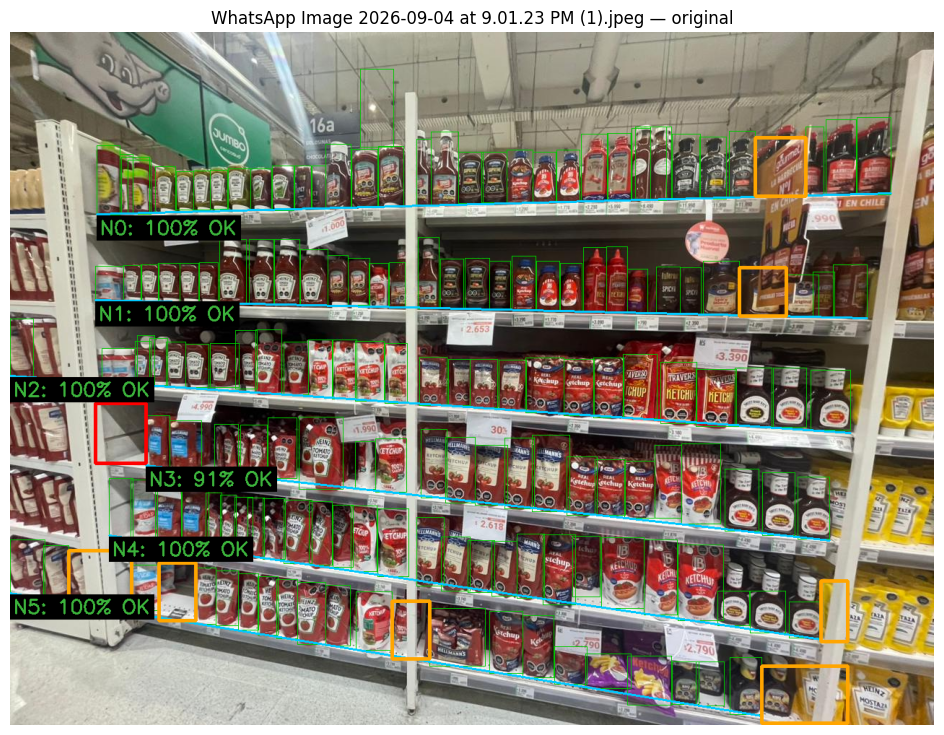


=== WhatsApp Image 2026-09-04 at 9.01.23 PM.jpeg ===
Calidad: resolución 960x1280 | brillo 129 | contraste 56 | nitidez 346 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 78 | Niveles analizados: 4
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 4 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 88% [OK] | 1 hueco(s) | faltan ~2 producto(s) | 3 posible(s) producto(s) no detectado(s)


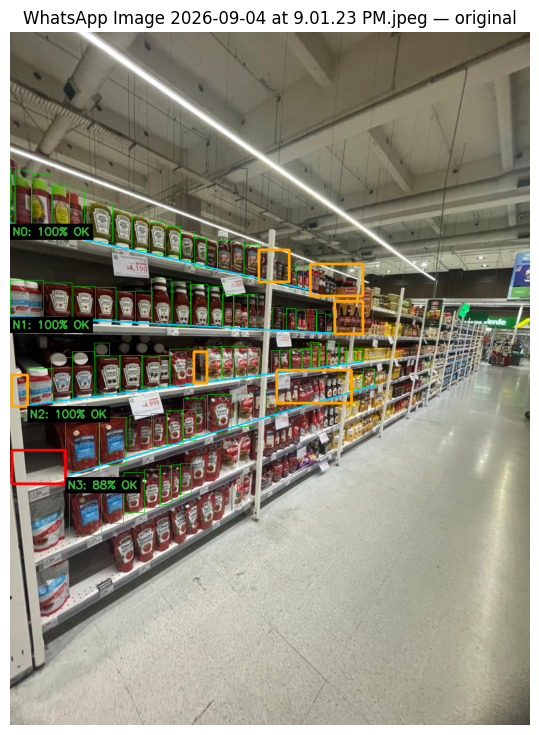


=== WhatsApp Image 2026-09-04 at 9.01.24 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 119 | contraste 60 | nitidez 950 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 227 | Niveles analizados: 8
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 6 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 92% [OK] | 1 hueco(s) | faltan ~4 producto(s) | 36 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 98% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 29 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 5: ocupación 95% [OK] | 1 hueco(s) | faltan ~2 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 6: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 2 posible(s) producto(

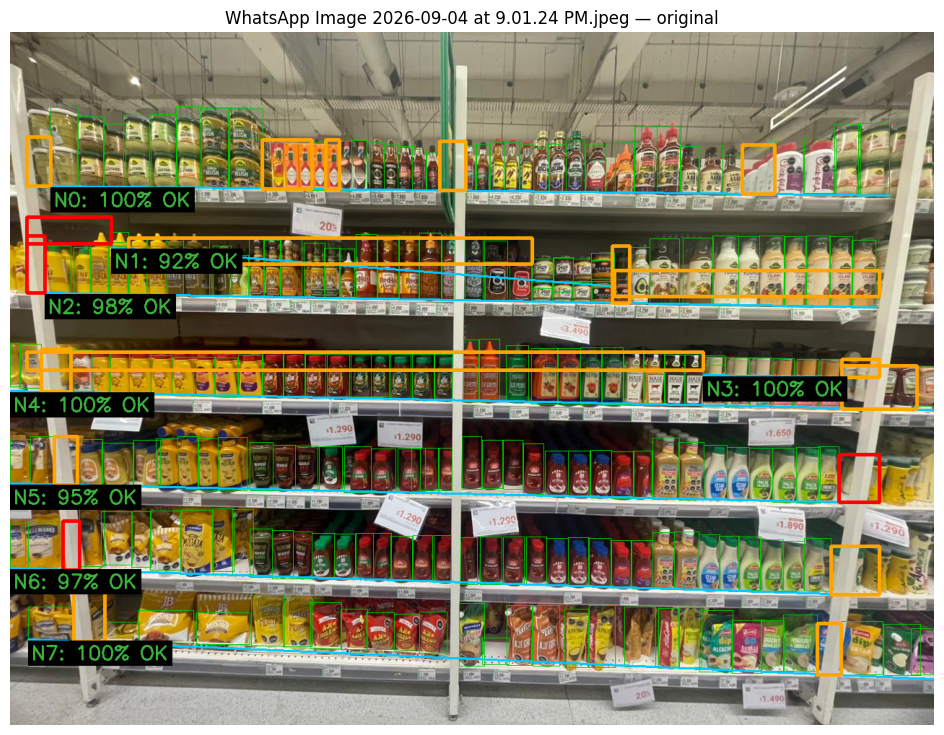


=== WhatsApp Image 2026-09-04 at 9.01.25 PM (1).jpeg ===
Calidad: resolución 1280x960 | brillo 122 | contraste 62 | nitidez 1227 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N6 y N7 (verificar a mano)
Productos detectados: 180 | Niveles analizados: 10
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 24 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 78% [Atención] | 2 hueco(s) | faltan ~6 producto(s) | 8 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 6 posible(s) producto(s) no detectado(s)
  * Nivel 5: ocupación 93% [OK] | 1 hueco(s) | faltan ~2 producto(s) | 21 posible(s) producto(s) no detectado(s)
  * Nivel 6: ocupación 100% [OK] | 0 hueco(s) | faltan ~0

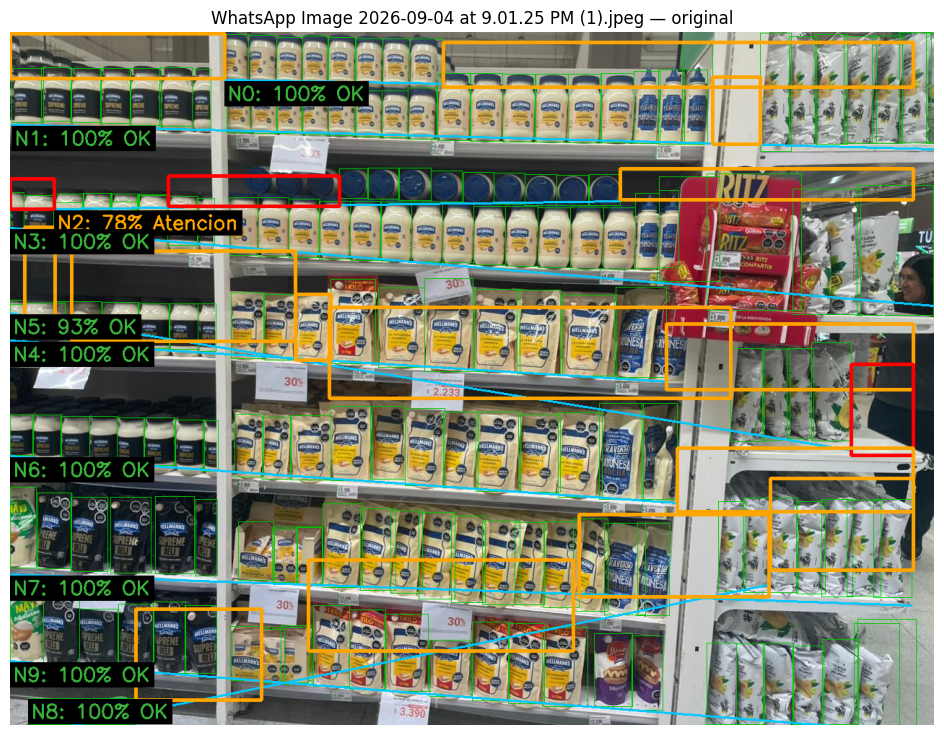


=== WhatsApp Image 2026-09-04 at 9.01.25 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 119 | contraste 65 | nitidez 1291 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 227 | Niveles analizados: 8
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 96% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 3: ocupación 93% [OK] | 1 hueco(s) | faltan ~2 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 5: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 6: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 7: ocupación 

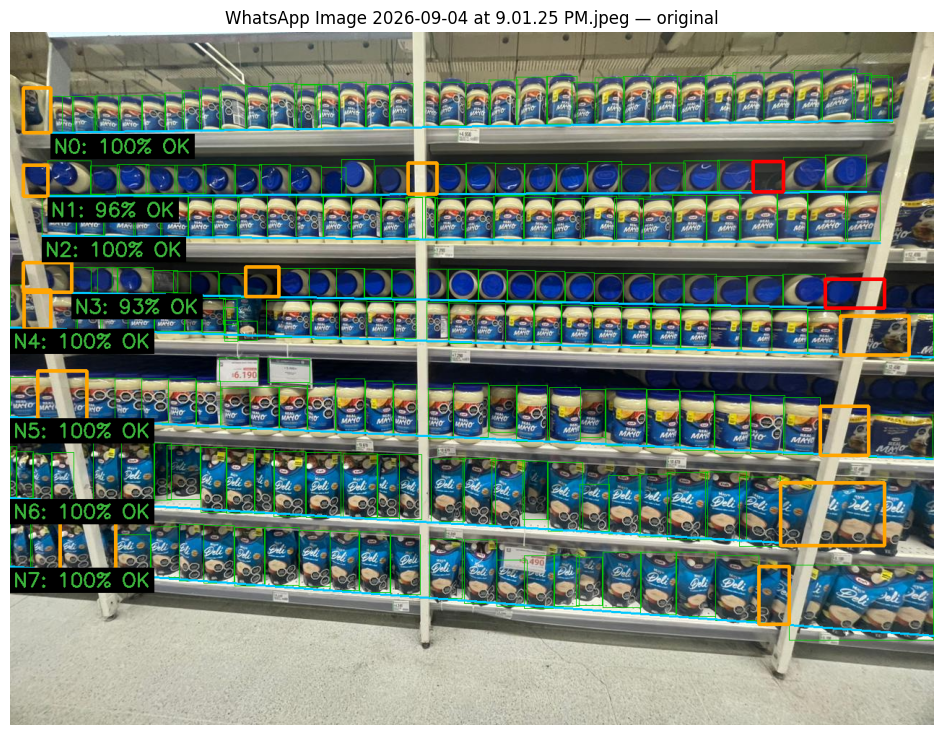


=== WhatsApp Image 2026-09-04 at 9.01.26 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 102 | contraste 70 | nitidez 1229 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 179 | Niveles analizados: 5
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 11 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 95% [OK] | 2 hueco(s) | faltan ~2 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 93% [OK] | 2 hueco(s) | faltan ~3 producto(s)
  * Nivel 3: ocupación 96% [OK] | 2 hueco(s) | faltan ~2 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 90% [OK] | 3 hueco(s) | faltan ~4 producto(s) | 4 posible(s) producto(s) no detectado(s)


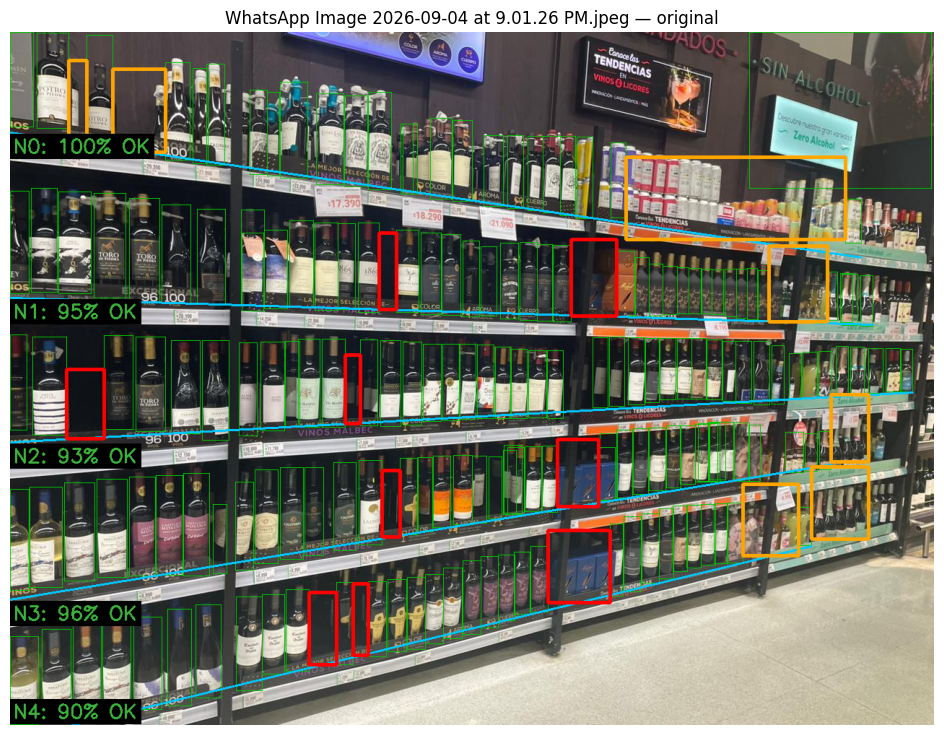


=== WhatsApp Image 2026-09-04 at 9.01.27 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 101 | contraste 71 | nitidez 1354 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 168 | Niveles analizados: 5
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 5 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 92% [OK] | 3 hueco(s) | faltan ~3 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 95% [OK] | 2 hueco(s) | faltan ~2 producto(s)


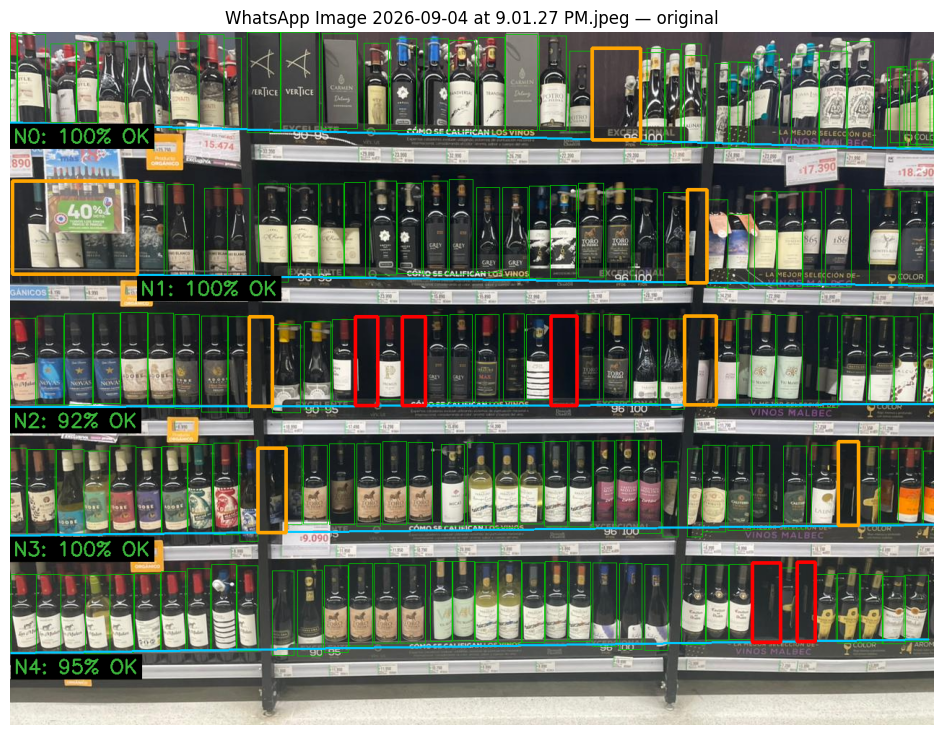


=== WhatsApp Image 2026-09-04 at 9.01.28 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 116 | contraste 70 | nitidez 1118 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 194 | Niveles analizados: 5
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 25 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 96% [OK] | 2 hueco(s) | faltan ~2 producto(s) | 17 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 95% [OK] | 3 hueco(s) | faltan ~3 producto(s) | 5 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 97% [OK] | 2 hueco(s) | faltan ~2 producto(s) | 8 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 93% [OK] | 2 hueco(s) | faltan ~4 producto(s) | 14 posible(s) producto(s) no detectado(s)


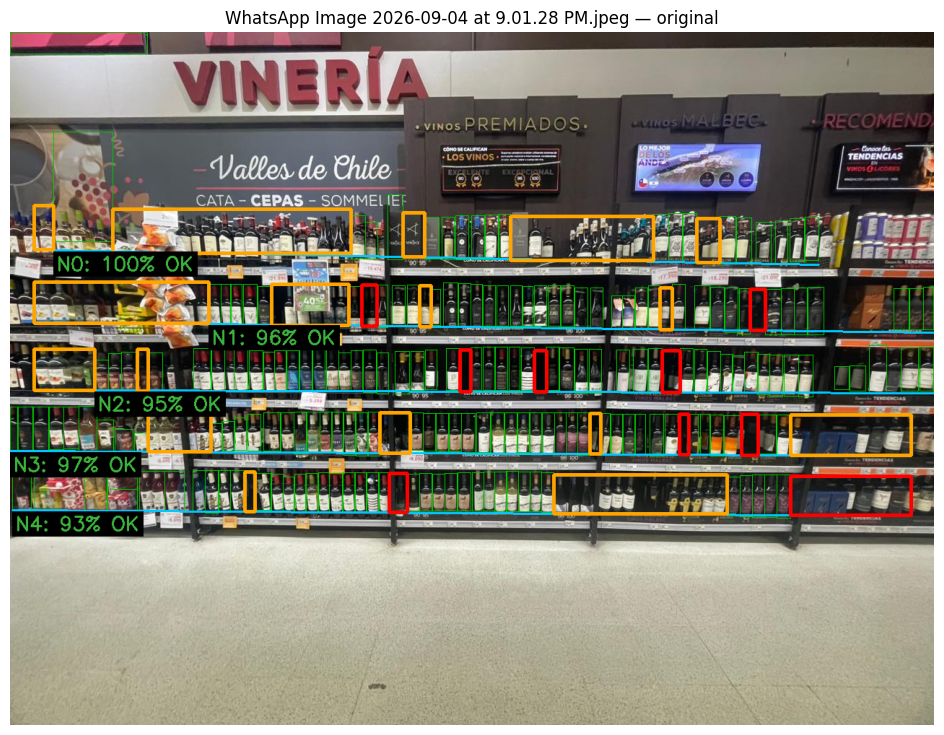


=== WhatsApp Image 2026-09-04 at 9.01.30 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 129 | contraste 70 | nitidez 883 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 106 | Niveles analizados: 5
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 1: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s)
  * Nivel 2: ocupación 96% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 93% [OK] | 1 hueco(s) | faltan ~2 producto(s) | 8 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 88% [OK] | 1 hueco(s) | faltan ~2 producto(s) | 9 posible(s) producto(s) no detectado(s)


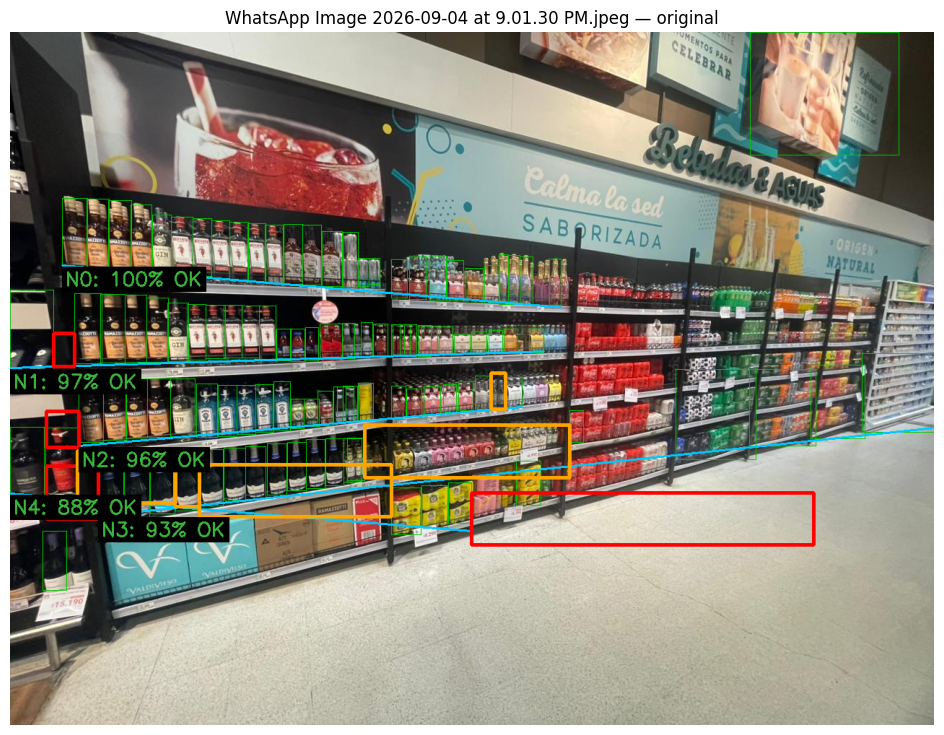


=== WhatsApp Image 2026-09-04 at 9.01.32 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 109 | contraste 68 | nitidez 1240 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 149 | Niveles analizados: 5
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 9 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 4 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)


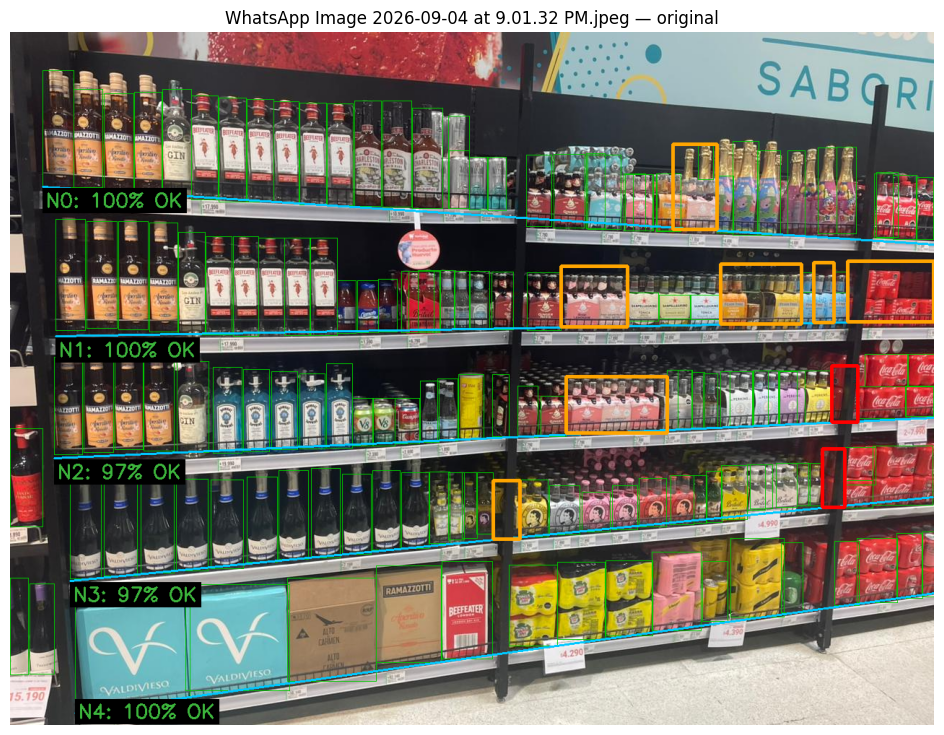


=== WhatsApp Image 2026-09-04 at 9.01.34 PM.jpeg ===
Calidad: resolución 960x1280 | brillo 119 | contraste 66 | nitidez 246 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 22 | Niveles analizados: 3
  * Nivel 0: ocupación 69% [Atención] | 1 hueco(s) | faltan ~4 producto(s) | 5 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 15 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)


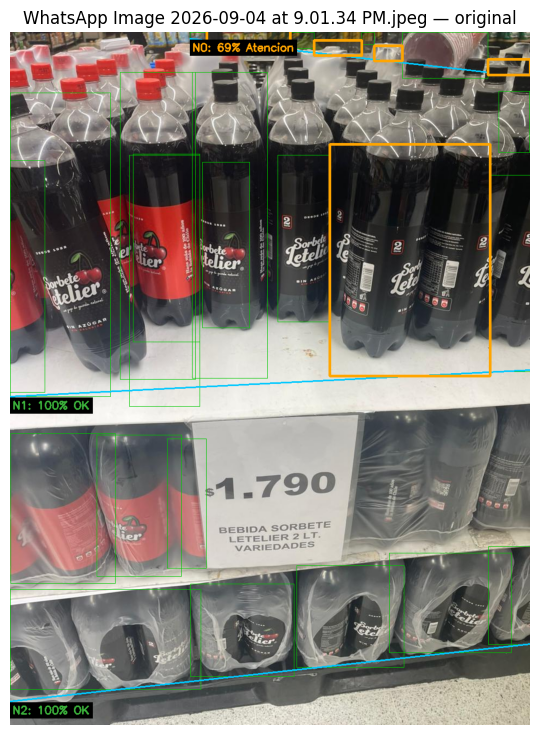


=== WhatsApp Image 2026-09-04 at 9.01.38 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 130 | contraste 62 | nitidez 802 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 85 | Niveles analizados: 4
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 9 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 9 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 4 posible(s) producto(s) no detectado(s)


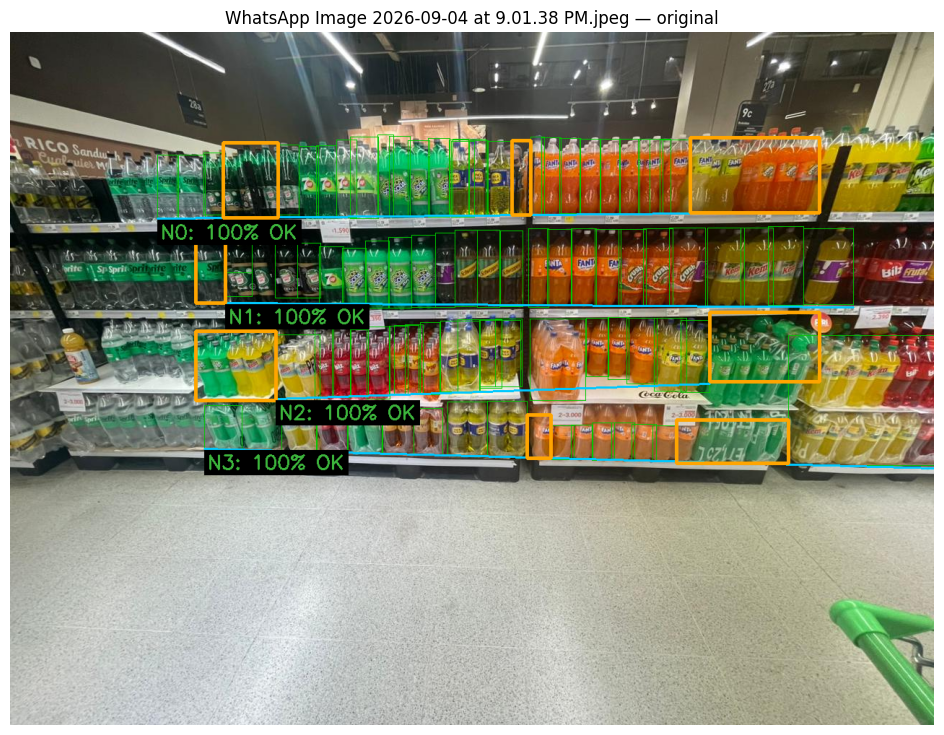


=== WhatsApp Image 2026-09-04 at 9.01.41 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 115 | contraste 50 | nitidez 870 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 116 | Niveles analizados: 4
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 16 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 3: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 12 posible(s) producto(s) no detectado(s)


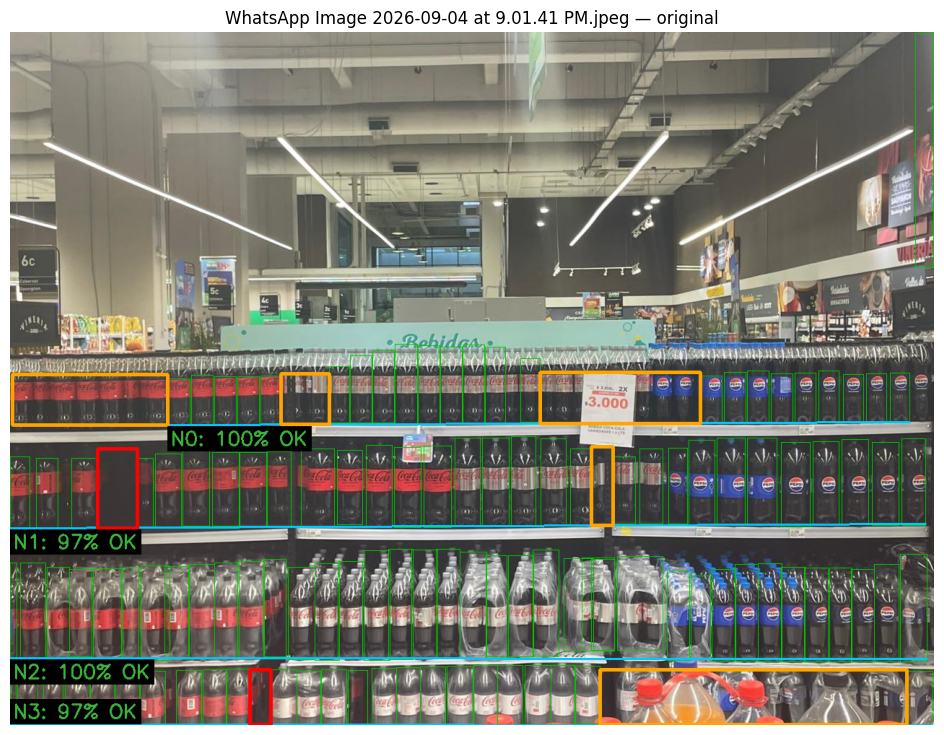


=== WhatsApp Image 2026-09-04 at 9.01.44 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 106 | contraste 70 | nitidez 1110 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 40 | Niveles analizados: 3
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 5 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 11 posible(s) producto(s) no detectado(s)


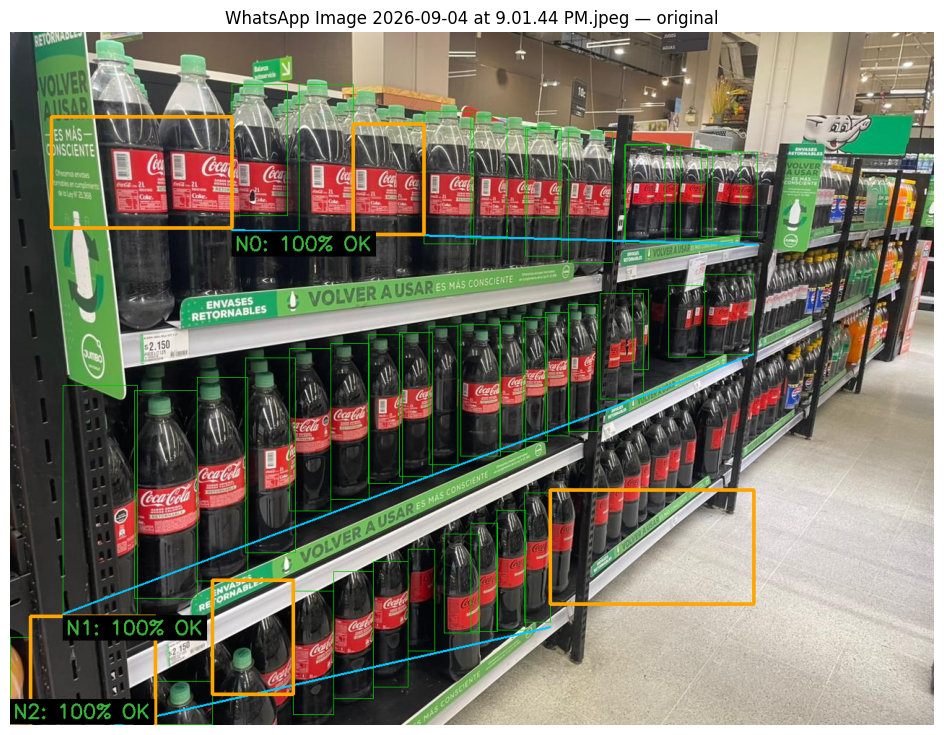


=== WhatsApp Image 2026-09-04 at 9.01.45 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 94 | contraste 69 | nitidez 1122 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 92 | Niveles analizados: 3
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 96% [OK] | 1 hueco(s) | faltan ~1 producto(s)


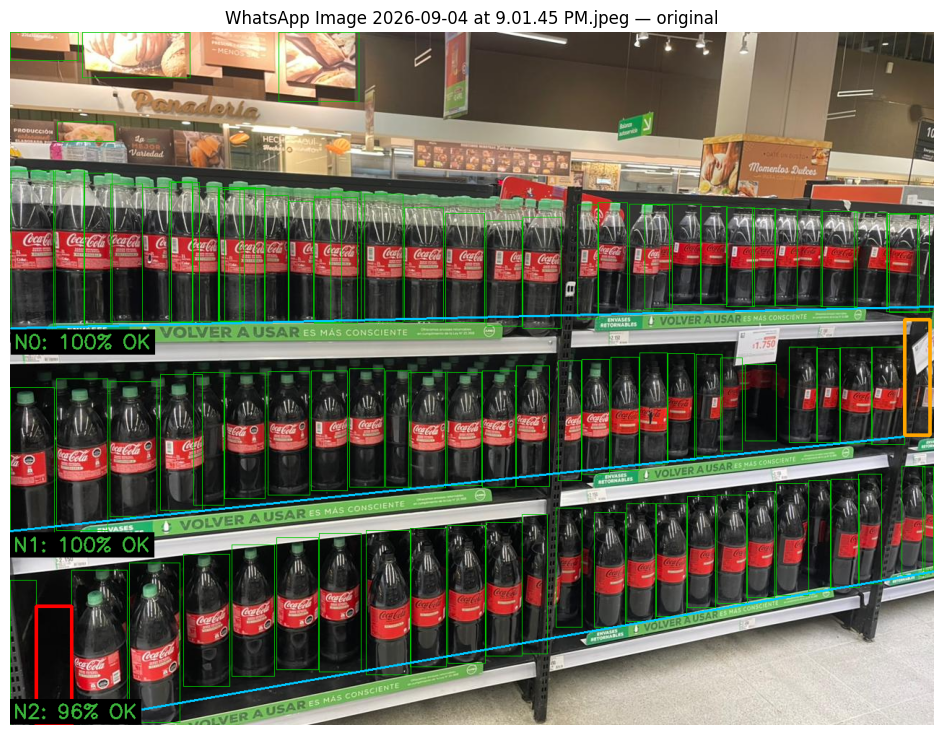


=== WhatsApp Image 2026-09-04 at 9.01.46 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 118 | contraste 67 | nitidez 1252 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N1 y N2 (verificar a mano)
  ⚠️ posible nivel sin productos entre N9 y N10 (verificar a mano)
  ⚠️ posible nivel sin productos entre N13 y N14 (verificar a mano)
  ⚠️ posible nivel sin productos entre N14 y N15 (verificar a mano)
Productos detectados: 299 | Niveles analizados: 16
  * Nivel 0: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 9 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 5 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 88% [OK] | 2 hueco(s) | faltan ~3 producto(s) | 15 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 16 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 97% [OK] | 1 hueco(s) | 

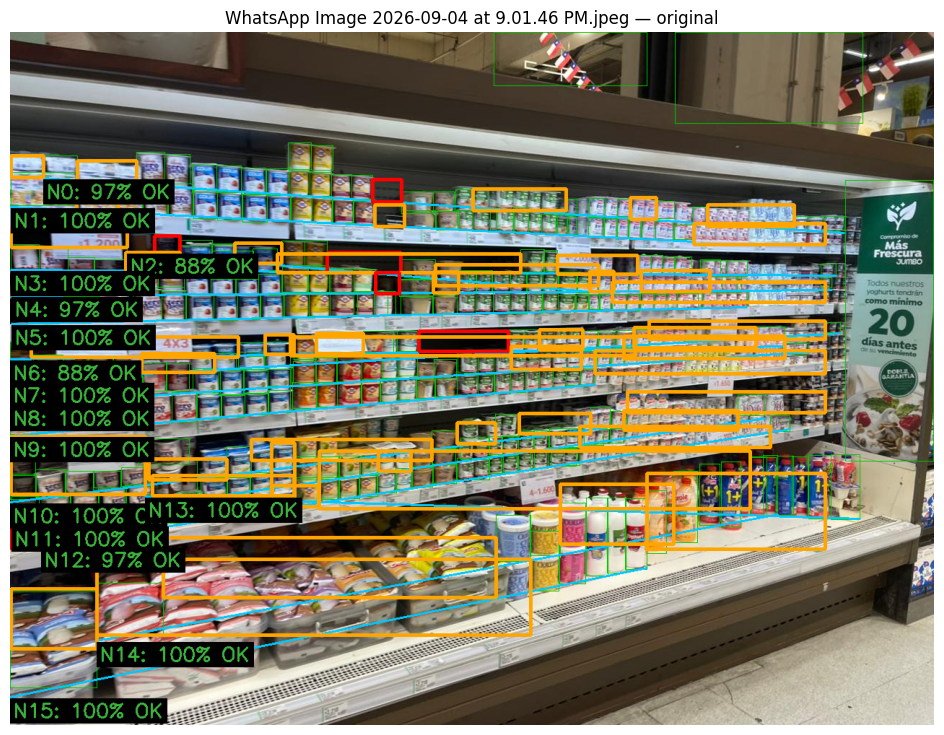


=== WhatsApp Image 2026-09-04 at 9.02.47 PM (1).jpeg ===
Calidad: resolución 1280x960 | brillo 117 | contraste 54 | nitidez 769 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N0 y N1 (verificar a mano)
  ⚠️ posible nivel sin productos entre N6 y N7 (verificar a mano)
  ⚠️ posible nivel sin productos entre N10 y N11 (verificar a mano)
  ⚠️ posible nivel sin productos entre N14 y N15 (verificar a mano)
Productos detectados: 260 | Niveles analizados: 16
  * Nivel 0: ocupación 91% [OK] | 2 hueco(s) | faltan ~2 producto(s) | 8 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 16 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 85% [OK] | 1 hueco(s) | faltan ~4 producto(s) | 12 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s)

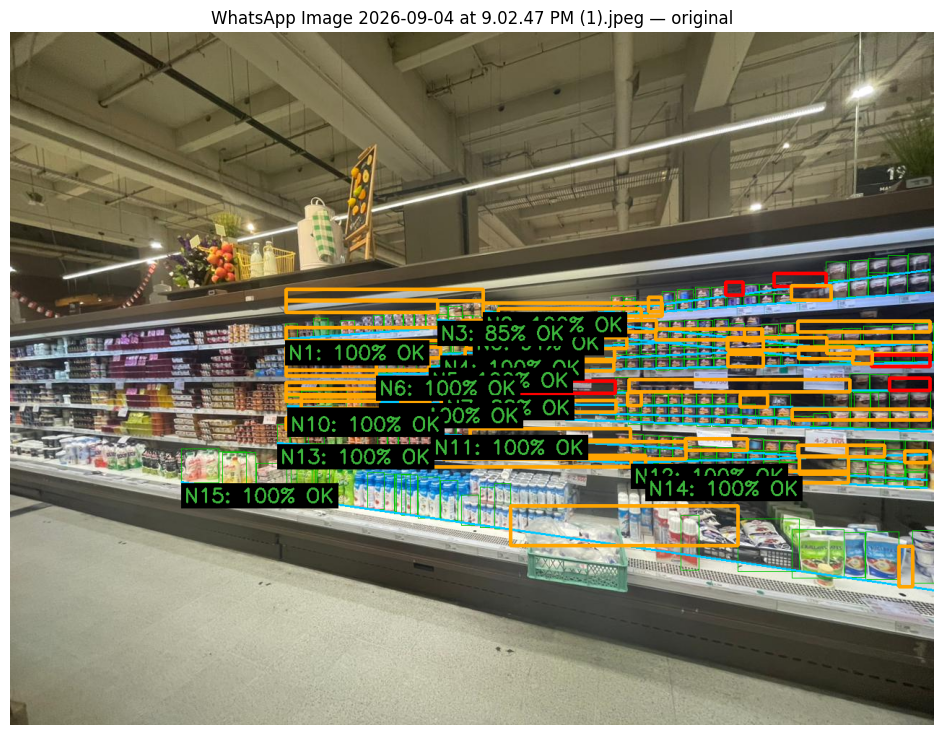


=== WhatsApp Image 2026-09-04 at 9.02.47 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 128 | contraste 57 | nitidez 1029 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N1 y N2 (verificar a mano)
  ⚠️ posible nivel sin productos entre N4 y N5 (verificar a mano)
Productos detectados: 126 | Niveles analizados: 8
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 10 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 2: ocupación 29% [Reponer] | 2 hueco(s) | faltan ~42 producto(s) | 12 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 67% [Atención] | 2 hueco(s) | faltan ~10 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 5: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 25 posible(s) producto(s) no detectado(s)
  * Nivel 6: ocupación 100% [OK

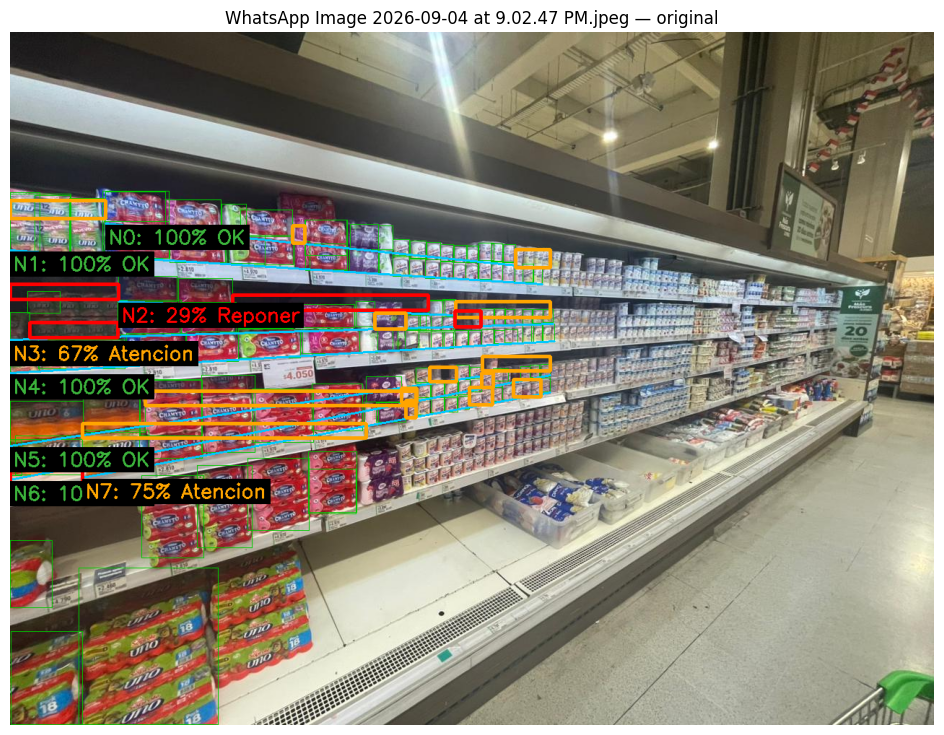


=== WhatsApp Image 2026-09-04 at 9.02.48 PM (1).jpeg ===
Calidad: resolución 1280x960 | brillo 125 | contraste 61 | nitidez 1169 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
Productos detectados: 90 | Niveles analizados: 3
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 9 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 11 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)


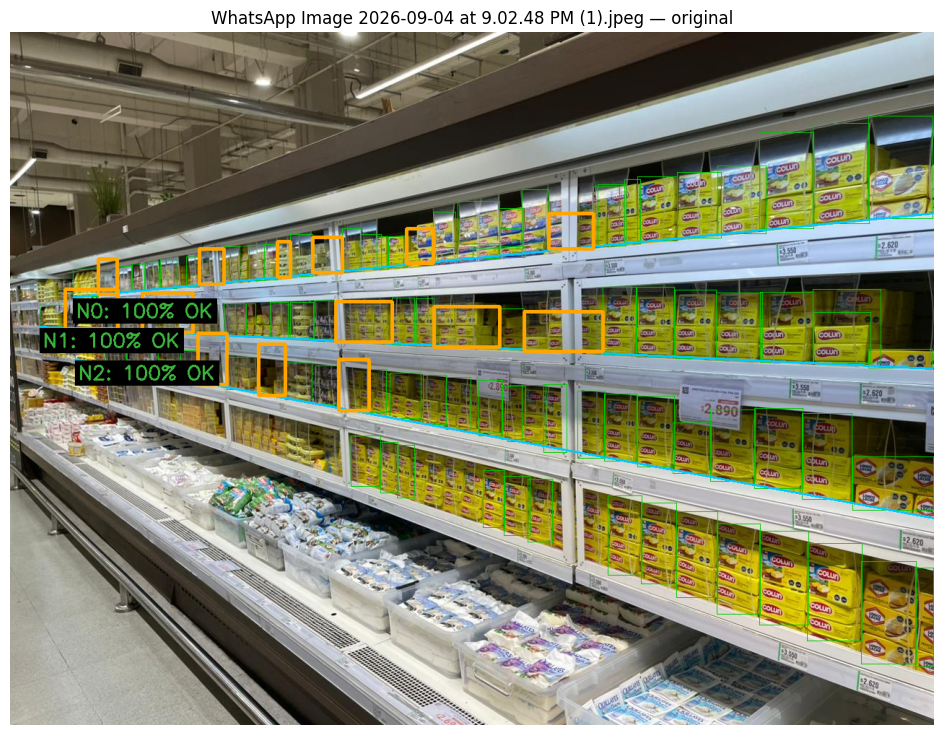


=== WhatsApp Image 2026-09-04 at 9.02.48 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 120 | contraste 65 | nitidez 1461 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N11 y N12 (verificar a mano)
Productos detectados: 238 | Niveles analizados: 16
  * Nivel 0: ocupación 94% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 4 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1930 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 95% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 15 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 5: ocupación 90% [OK] | 2 hueco(s) | faltan ~2 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 6: ocupació

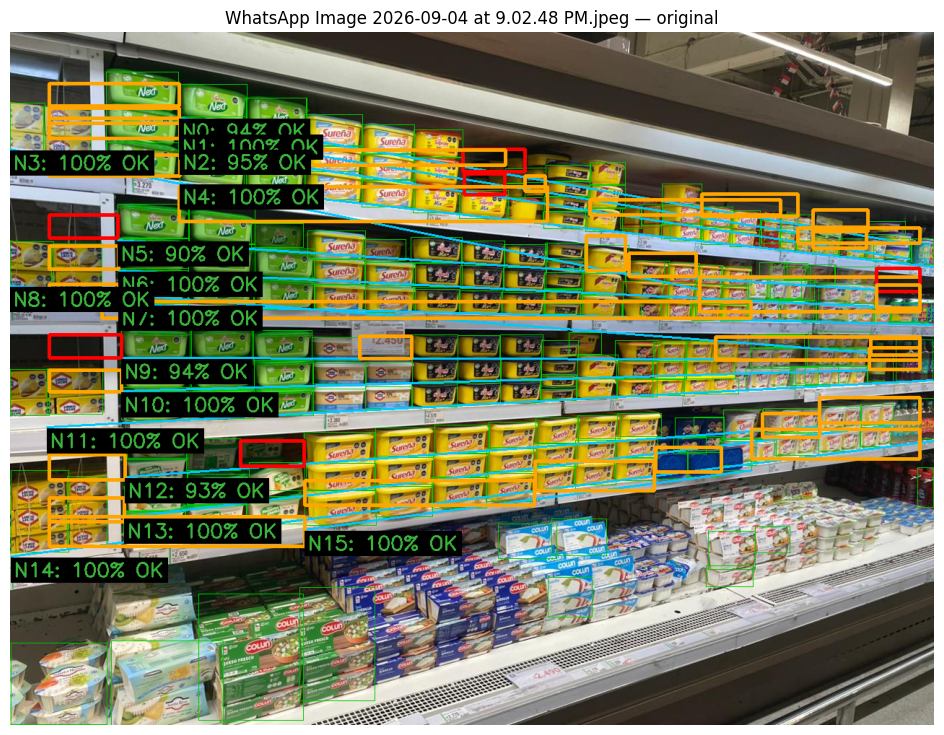


=== WhatsApp Image 2026-09-04 at 9.02.49 PM (1).jpeg ===
Calidad: resolución 1280x960 | brillo 115 | contraste 67 | nitidez 1528 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N8 y N9 (verificar a mano)
  ⚠️ posible nivel sin productos entre N9 y N10 (verificar a mano)
Productos detectados: 197 | Niveles analizados: 12
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 37 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 28 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 24 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 5: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 25 posible(s) producto(s) no detectado(s)
  * Nivel 6: ocupación 100% [OK] | 

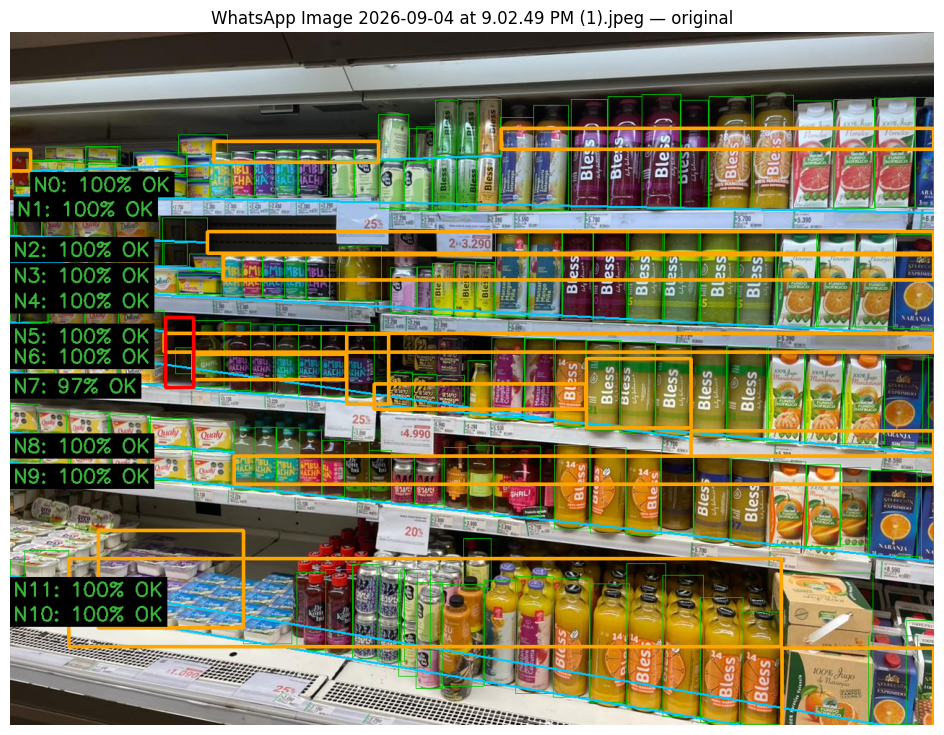


=== WhatsApp Image 2026-09-04 at 9.02.49 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 119 | contraste 66 | nitidez 1223 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N2 y N3 (verificar a mano)
  ⚠️ posible nivel sin productos entre N5 y N6 (verificar a mano)
  ⚠️ posible nivel sin productos entre N9 y N10 (verificar a mano)
  ⚠️ posible nivel sin productos entre N12 y N13 (verificar a mano)
Productos detectados: 197 | Niveles analizados: 14
  * Nivel 0: ocupación 71% [Atención] | 3 hueco(s) | faltan ~4 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) pr

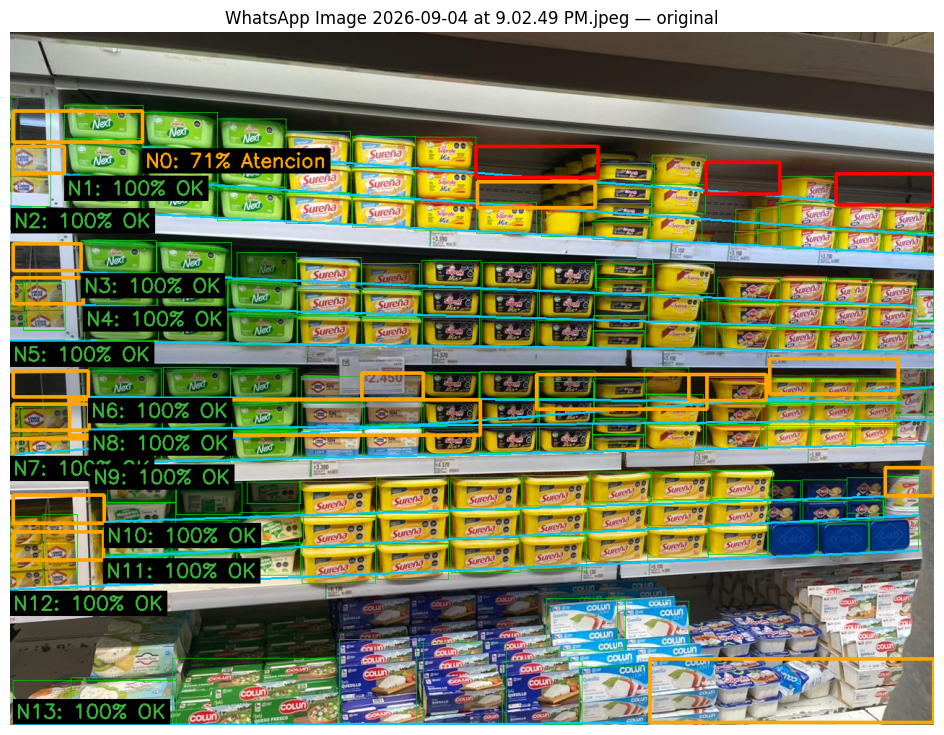


=== WhatsApp Image 2026-09-04 at 9.02.50 PM (1).jpeg ===
Calidad: resolución 960x1280 | brillo 119 | contraste 62 | nitidez 549 | reflejos 0%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N3 y N4 (verificar a mano)
Productos detectados: 94 | Niveles analizados: 5
  * Nivel 0: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 1: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 15 posible(s) producto(s) no detectado(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 3 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 11 posible(s) producto(s) no detectado(s)


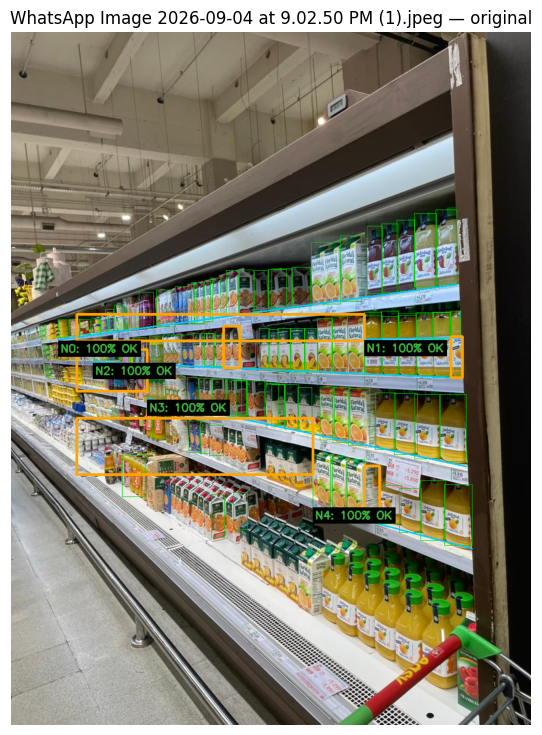


=== WhatsApp Image 2026-09-04 at 9.02.50 PM.jpeg ===
Calidad: resolución 1280x960 | brillo 115 | contraste 69 | nitidez 1537 | reflejos 1%
Mejora aplicada: no (calidad suficiente)
  ⚠️ posible nivel sin productos entre N0 y N1 (verificar a mano)
Productos detectados: 150 | Niveles analizados: 6
  * Nivel 0: ocupación 96% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 16 posible(s) producto(s) no detectado(s)
  * Nivel 1: ocupación 85% [OK] | 1 hueco(s) | faltan ~5 producto(s)
  * Nivel 2: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s)
  * Nivel 3: ocupación 100% [OK] | 0 hueco(s) | faltan ~0 producto(s) | 1 posible(s) producto(s) no detectado(s)
  * Nivel 4: ocupación 97% [OK] | 1 hueco(s) | faltan ~1 producto(s) | 2 posible(s) producto(s) no detectado(s)
  * Nivel 5: ocupación 96% [OK] | 1 hueco(s) | faltan ~1 producto(s)


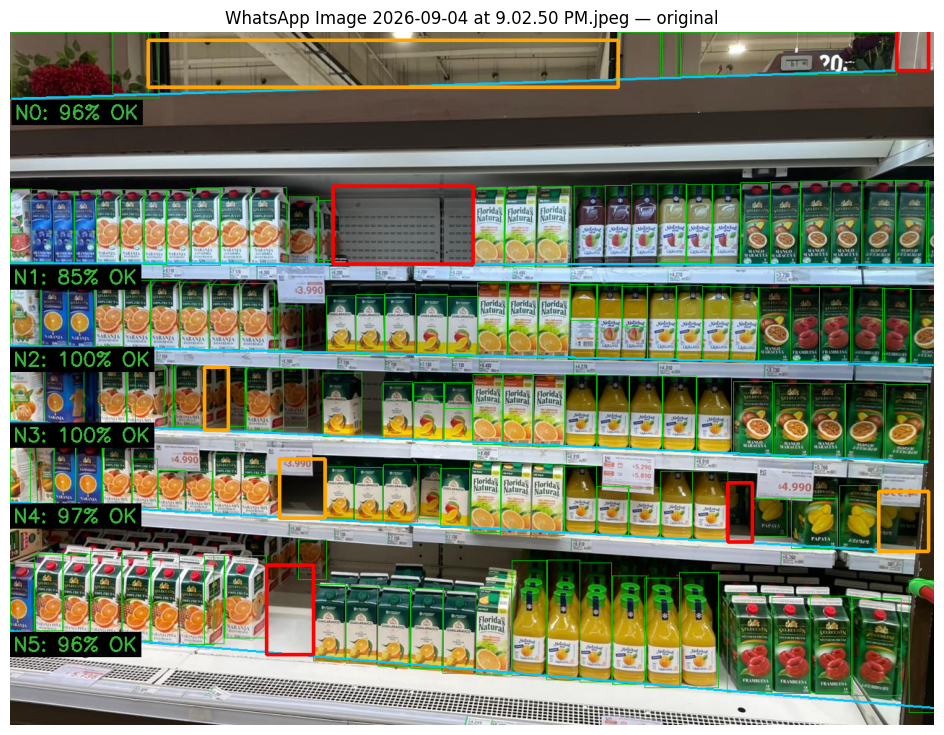

In [11]:
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

def obtener_imagenes():
    if IMAGES_SOURCE == 'carpeta':
        rutas = sorted(p for p in INPUT_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        if not rutas:
            raise ValueError(f"No hay imágenes en {INPUT_DIR}")
        return rutas
    from google.colab import files
    subidas = files.upload()
    if not subidas:
        raise ValueError("No se subió ninguna imagen.")
    return [Path(n) for n in subidas if Path(n).suffix.lower() in IMAGE_EXTENSIONS]

rutas = obtener_imagenes()
print(f"[*] {len(rutas)} imagen(es) a analizar\n")

carpeta_salida = OUTPUT_DIR / datetime.now().strftime('%Y%m%d_%H%M%S')
(carpeta_salida / 'anotadas').mkdir(parents=True, exist_ok=True)

resultados, filas_img, filas_niv = [], [], []
for ruta in rutas:
    try:
        r = procesar(ruta)
    except Exception as e:
        print(f"[!] {ruta}: {e}\n")
        continue
    resultados.append(r)
    imprimir_reporte(r)

    cv2.imwrite(str(carpeta_salida / 'anotadas' / f"{Path(ruta).stem}_analisis.jpg"), r['anotada'])
    plt.figure(figsize=(14, 9))
    plt.imshow(cv2.cvtColor(r['anotada'], cv2.COLOR_BGR2RGB))
    plt.title(f"{r['archivo']} — {'mejorada' if r['mejora_aplicada'] else 'original'}")
    plt.axis('off')
    plt.show()
    print()

    q, niv = r['calidad'], r['niveles']
    filas_img.append(dict(
        archivo=r['archivo'], mejora_aplicada=r['mejora_aplicada'], motivo=r['motivo'],
        brillo=round(q['brillo']), contraste=round(q['contraste']), nitidez=round(q['nitidez']),
        avisos=' | '.join(q['avisos']), productos=r['n_productos'], niveles=r['n_niveles'],
        ocupacion_media=round(sum(n['ocupacion'] for n in niv) / len(niv), 1) if niv else None,
        niveles_a_reponer=sum(n['estado'] == 'Reponer' for n in niv),
        faltantes_est=sum(n['faltantes_est'] for n in niv),
        posibles_no_detectados=sum(n['posibles_no_detectados'] for n in niv),
    ))
    for n in niv:
        filas_niv.append(dict(archivo=r['archivo'], **{k: v for k, v in n.items() if k not in ('y_top', 'y_bottom')}))

## 5. Resumen y exportación
Tablas por imagen y por nivel; también quedan en `resultados/<fecha>/` en Drive, junto con `detecciones.json`.

In [12]:
df_img = pd.DataFrame(filas_img)
df_niv = pd.DataFrame(filas_niv)

import json
# Detecciones crudas del modelo: sirven para depurar el análisis de la góndola sin volver a correr el modelo
detecciones = {
    r['archivo']: [dict(x1=round(d[0], 1), y1=round(d[1], 1), x2=round(d[2], 1), y2=round(d[3], 1),
                        clase=model.names[d[4]], conf=round(d[5], 3)) for d in r['dets']]
    for r in resultados
}
(carpeta_salida / 'detecciones.json').write_text(json.dumps(detecciones, ensure_ascii=False))

df_img.to_csv(carpeta_salida / 'resumen_por_imagen.csv', index=False, encoding='utf-8-sig')
df_niv.to_csv(carpeta_salida / 'detalle_por_nivel.csv', index=False, encoding='utf-8-sig')

print(f"[OK] Resultados guardados en: {carpeta_salida}")
display(df_img)
display(df_niv)

[OK] Resultados guardados en: /content/drive/MyDrive/tesis_colab/resultados/20261019_140628


,archivo,mejora_aplicada,motivo,brillo,contraste,nitidez,avisos,productos,niveles,ocupacion_media,niveles_a_reponer,faltantes_est,posibles_no_detectados
0,WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg,False,calidad suficiente,123,64,1234,,161,6,98.5,0,2,11
1,WhatsApp Image 2026-09-04 at 9.01.23 PM.jpeg,False,calidad suficiente,129,56,346,,78,4,97.0,0,2,10
2,WhatsApp Image 2026-09-04 at 9.01.24 PM.jpeg,False,calidad suficiente,119,60,950,,227,8,97.7,0,8,80
3,WhatsApp Image 2026-09-04 at 9.01.25 PM (1).jpeg,False,calidad suficiente,122,62,1227,posible nivel sin productos entre N6 y N7 (ver...,180,10,97.1,0,8,86
4,WhatsApp Image 2026-09-04 at 9.01.25 PM.jpeg,False,calidad suficiente,119,65,1291,,227,8,98.7,0,3,17
5,WhatsApp Image 2026-09-04 at 9.01.26 PM.jpeg,False,calidad suficiente,102,70,1229,,179,5,94.8,0,11,19
6,WhatsApp Image 2026-09-04 at 9.01.27 PM.jpeg,False,calidad suficiente,101,71,1354,,168,5,97.3,0,5,11
7,WhatsApp Image 2026-09-04 at 9.01.28 PM.jpeg,False,calidad suficiente,116,70,1118,,194,5,96.2,0,11,69
8,WhatsApp Image 2026-09-04 at 9.01.30 PM.jpeg,False,calidad suficiente,129,70,883,,106,5,94.7,0,6,18
9,WhatsApp Image 2026-09-04 at 9.01.32 PM.jpeg,False,calidad suficiente,109,68,1240,,149,5,98.9,0,2,15


,archivo,nivel,productos,ocupacion,huecos,faltantes_est,posibles_no_detectados,estado,vacio_total
0,WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg,0,34,100.0,0,0,2,OK,False
1,WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg,1,30,100.0,0,0,2,OK,False
2,WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg,2,28,100.0,0,0,0,OK,False
3,WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg,3,21,91.3,1,2,0,OK,False
4,WhatsApp Image 2026-09-04 at 9.01.23 PM (1).jpeg,4,27,100.0,0,0,1,OK,False
...,...,...,...,...,...,...,...,...,...
169,WhatsApp Image 2026-09-04 at 9.02.50 PM.jpeg,1,29,85.3,1,5,0,OK,False
170,WhatsApp Image 2026-09-04 at 9.02.50 PM.jpeg,2,33,100.0,0,0,0,OK,False
171,WhatsApp Image 2026-09-04 at 9.02.50 PM.jpeg,3,29,100.0,0,0,1,OK,False
172,WhatsApp Image 2026-09-04 at 9.02.50 PM.jpeg,4,26,96.6,1,1,2,OK,False
